In [1]:
# --- path bootstrap: find the repo root (contains noise_module/noise_module/__init__.py)
import os, sys, warnings
from pathlib import Path

_p = Path.cwd().resolve()
while not (_p / "noise_module" / "noise_module" / "__init__.py").exists() and _p != _p.parent:
    _p = _p.parent
REPO_ROOT = _p
PKG_DIR = REPO_ROOT / "noise_module"          # the installable package lives here
if str(PKG_DIR) not in sys.path:
    sys.path.insert(0, str(PKG_DIR))
warnings.filterwarnings("ignore", category=DeprecationWarning)
print("repo root :", REPO_ROOT)

repo root : /tmp/claude-0/-home-claude/bafb3ccb-3bbd-572e-bbf2-7aa57859deef/scratchpad/mockrepo


# `noise_module` for DELight — demo notebook

*What this notebook shows, in the order of the demo:*

1. **The reference MMC noise budget** (Johnson, SQUID, thermodynamic, Er-spin) and the parametric model the package fits to it.
2. **How a PSD becomes a time series** — the exact discrete convention, and the statistical gates that prove the synthesiser reproduces the target.
3. **Pulse template and optimal filter** — amplitude recovery on synthetic traces, and *where in frequency the resolution comes from*.
4. **The readout-bandwidth decision** — why alias-folding a 30 MHz budget into a 1 MHz DAQ is a ×5.7 effect on baseline resolution, and what the package now does by default.
5. **Stressors** — slow non-stationarity (bath temperature), mains lines, pile-up tails.
6. **Multichannel synthesis with a physical cross-spectrum** — private sensor noise plus a shared low-frequency component.
7. What is *not* in the model yet.

Units: the budget files are one-sided amplitude spectral densities in µΦ₀/√Hz (flux at the SQUID input). Everything below stays in flux units; converting to eV needs the detector's ∂Φ/∂E, which is not part of the budget.

In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch

from noise_module import (
    __version__, NoiseGenerator, TemporalNoiseWrapper, ArtifactInjector,
    MultiChannelNoiseGenerator, ValidationConfig, validate_stationary_gaussian,
    White, PowerLaw, RollOff, Lorentzian, Line, CompositeSpectrum,
)
from noise_module import al2o3_athermal as A
from noise_module import psd_resampling as pr
from noise_module.fit_al2o3_athermal import load_all_components, load_asd, native_grid_psd
from noise_module.templates import pulse_template_2

C = {"Johnson": "#2a78d6", "SQUID": "#eb6834", "TD": "#1baf7a", "Er": "#eda100", "total": "#1a1a19", "sim": "#e87ba4"}
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "grid.color": "#e6e5df", "axes.grid": True, "figure.dpi": 110})

FS = A.DEFAULT_SAMPLING_FREQUENCY      # 1 MHz
N  = A.DEFAULT_SAMPLES                 # 131072 samples = 131 ms, df = 7.63 Hz
print("noise_module", __version__, "| fs =", FS, "Hz | N =", N, "| df =", FS / N, "Hz")

noise_module 0.3.1 | fs = 1000000.0 Hz | N = 131072 | df = 7.62939453125 Hz


## 1. The reference MMC noise budget

A metallic magnetic calorimeter reads the temperature of a paramagnetic (Ag:Er / Au:Er) sensor as a change of magnetisation, picked up by a meander coil and read by a dc-SQUID. Referred to flux at the SQUID, the standard budget (Fleischmann, Enss, Seidel; Kempf et al. 2018) has four intrinsic terms:

| term | physics | spectral form used here |
|---|---|---|
| **TD** — thermodynamic energy fluctuations | energy exchanged between spins, electrons and the bath through the thermal links; the fundamental calorimeter limit | $S_{\rm TD}(f) = S_0\,/\,[1+(2\pi f\tau_1)^2]$ with $\tau_1 = 1$ ms (the sensor–bath time) |
| **Johnson** — magnetic Johnson noise | thermal currents in the metallic sensor and absorber couple flux into the pickup coil; $\sqrt{S_\Phi}\propto\mu_0\sqrt{\sigma k_B T V}$ | white |
| **Er** — spin 1/f noise | slow fluctuations of the Er³⁺ moments, ≈ 0.1 µ_B²/Hz per ion, essentially temperature independent | $S_0\,f^{-0.9}$ |
| **SQUID** — flux noise of the readout | white floor plus 1/f below ~100 Hz | $S_0 + A/f$ |

The two-body TD model actually has *two* Lorentzians, $\alpha_0\,4\tau_0/(1+\omega^2\tau_0^2)+\alpha_1\,4\tau_1/(1+\omega^2\tau_1^2)$; the budget we were given contains only the $\tau_1$ term. That is a stated approximation, not something the package invents.

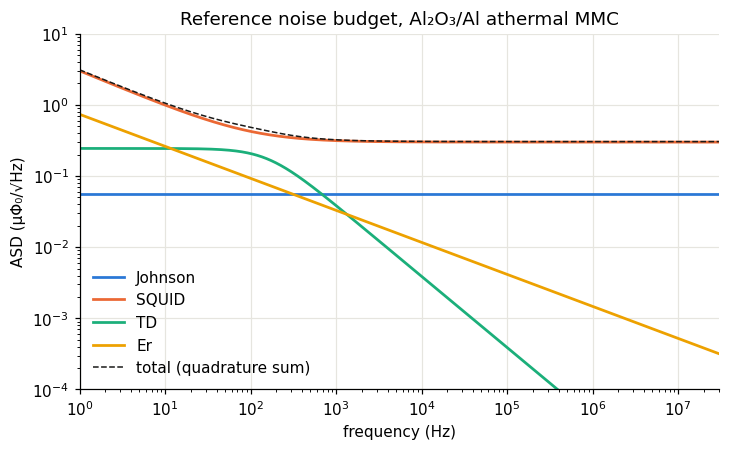

Fitted parameters (PSD space, µΦ₀²/Hz):
  Johnson  {'s0': 0.0030307426626081345}
  SQUID    {'s0': 0.08999999999999998, 'a': 9.0, 'knee_hz': 100.00000000000001}
  TD       {'s0': 0.05976157531368565, 'corner_hz': 159.15494309189538}
  Er       {'s0': 0.5442319404674618, 'alpha': -0.9}
Quadrature-sum check of the fit against total_noise.dat: {'median_ratio': 1.0, 'max_frac_dev': 2.220446049250313e-16, 'rms_frac_dev': 1.2924272004889344e-16}


In [3]:
comps = load_all_components()
f_nat, psd_nat = native_grid_psd(comps)
f_tot, asd_tot = load_asd("total_noise.dat")
fit_cfg = json.loads((A.DATA_DIR / "al2o3_athermal_fit.json").read_text())

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for name, (f, asd) in comps.items():
    ax.loglog(f, asd, color=C[name], lw=1.8, label=name)
ax.loglog(f_tot, asd_tot, color=C["total"], lw=1.0, ls="--", label="total (quadrature sum)")
ax.set(xlim=(1, 3e7), ylim=(1e-4, 10), xlabel="frequency (Hz)", ylabel="ASD (µΦ₀/√Hz)",
       title="Reference noise budget, Al₂O₃/Al athermal MMC")
ax.legend(frameon=False); plt.show()

print("Fitted parameters (PSD space, µΦ₀²/Hz):")
for k, v in fit_cfg["params"].items():
    print(f"  {k:8s} {v}")
print("Quadrature-sum check of the fit against total_noise.dat:", fit_cfg["validation"])

## 2. From PSD to time series — and proving it

The package defines the discrete process exactly (see `PAPER_CONVENTION.md`). With $P_k$ the one-sided PSD density at rFFT bin $k$ and NumPy's unnormalised `rfft`/`irfft`:

$$\mathbb{E}|X_k|^2 = \tfrac12 f_s N P_k \ \ (0<k<N/2),\qquad \mathbb{E}|X_k|^2 = f_s N P_k \ \ (k=0,\ N/2),$$

interior bins are circular complex Gaussian, $X_k = \sqrt{\mathbb{E}|X_k|^2}\,(\xi_1+i\xi_2)/\sqrt2$, endpoints real Gaussian, and then $\mathrm{Var}[x_t]=\sum_k P_k\,\Delta f$. Gaussian *moduli* matter: a constant-modulus random-phase sampler gives the right mean PSD but every record has identical per-bin power, so χ² or KS residual tests become meaningless.

The process is periodic on the grid (circulant covariance), and the DC bin is forced to zero, so a record has no sub-$\Delta f$ content — no baseline offset or slope. Real MMC records do have those; that is what the drift wrapper in §5 is for.

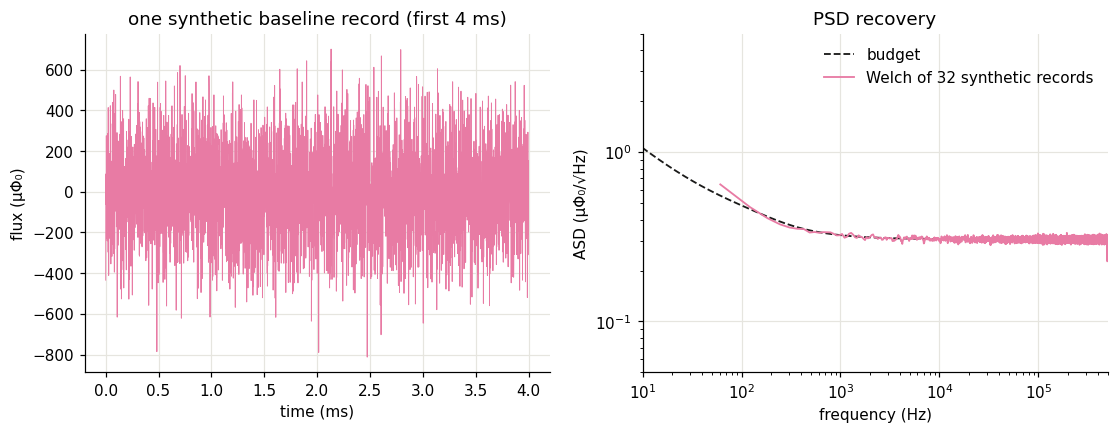

median ASD ratio (sim / model) = 0.9992, RMS fractional error = 0.023 (Welch estimator noise)
trace variance = 46636.2  vs  Σ P_k Δf = 46649.0  µΦ₀²


In [4]:
gen = A.noise_generator(sampling_frequency=FS, seed=1)   # analytic four-term composite, absolute units
X = gen.generate_ensemble(32, N)                          # (32, 131072)

fw, Pw = welch(X, fs=FS, nperseg=16384, detrend=False, axis=1)
Pw = Pw.mean(axis=0)
model, _ = A.load_composite().evaluate(fw, FS / 16384, zero_dc=True)
ok = (fw > 0) & (model > 0)
ratio = np.sqrt(Pw[ok] / model[ok])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
t = np.arange(4000) / FS * 1e3
ax[0].plot(t, X[0, :4000], lw=0.6, color=C["sim"]); ax[0].set(xlabel="time (ms)", ylabel="flux (µΦ₀)", title="one synthetic baseline record (first 4 ms)")
ax[1].loglog(f_tot, asd_tot, color=C["total"], lw=1.2, ls="--", label="budget")
ax[1].loglog(fw[ok], np.sqrt(Pw[ok]), color=C["sim"], lw=1.2, label="Welch of 32 synthetic records")
ax[1].set(xlim=(10, 5e5), ylim=(0.05, 5), xlabel="frequency (Hz)", ylabel="ASD (µΦ₀/√Hz)", title="PSD recovery")
ax[1].legend(frameon=False); plt.show()

_, dens = gen.build_psd_density(N)
print(f"median ASD ratio (sim / model) = {np.median(ratio):.4f}, RMS fractional error = {np.sqrt(np.mean((ratio-1)**2)):.3f} (Welch estimator noise)")
print(f"trace variance = {X.var():.1f}  vs  Σ P_k Δf = {np.sum(dens[1:]) * FS / N:.1f}  µΦ₀²")

The statistical gates below are what makes the synthesiser *validated* rather than *plausible*: total power, PSD shape, normality of the real and imaginary Fourier parts, exponential distribution of the normalised periodogram, Fourier skewness/kurtosis, whitened lag-1 autocorrelation, and the real-valuedness of the DC/Nyquist bins. Tolerances widen automatically with ensemble size so a small demo ensemble is not held to an impossible standard.

In [5]:
vres = validate_stationary_gaussian(A.noise_generator(sampling_frequency=FS, seed=7), 8192,
                                    ValidationConfig(ensemble_size=128))
print("passed:", vres.passed)
for gate, ok_ in vres.thresholds["gates"].items():
    print(f"  {gate:28s} {ok_}")
print({k: round(v, 4) for k, v in vres.statistics.items() if isinstance(v, float)})

passed: True
  power                        True
  psd                          True
  fourier_real_normality       True
  fourier_imag_normality       True
  time_marginal_normality      True
  periodogram_exponential      True
  fourier_skewness             True
  fourier_excess_kurtosis      True
  whitened_lag1                True
  dc_real_constraint           True
  nyquist_real_constraint      True
  dc_distribution              None
  nyquist_distribution         True
{'variance_mean': 46591.5452, 'target_variance': 46618.6432, 'relative_power_error': 0.0006, 'mean_relative_psd_error': 0.0696, 'fourier_skewness': -0.001, 'fourier_excess_kurtosis': -0.0004, 'fourier_real_normality_ks_statistic': 0.0059, 'fourier_real_normality_ks_pvalue': 0.994, 'fourier_imag_normality_ks_statistic': 0.0088, 'fourier_imag_normality_ks_pvalue': 0.8327, 'time_marginal_normality_ks_statistic': 0.0633, 'time_marginal_normality_ks_pvalue': 0.6609, 'normalized_periodogram_ks_statistic': 0.0082, 'norma

## 3. Pulse template, optimal filter, and where the resolution comes from

`signal.dat` is the magnitude of the detector's flux response; the package fits the causal two-exponential (Probst/Cait) template and recovers $\tau_{\rm in}=5\,\mu$s (rise) and $\tau_t = 1$ ms (decay) to $10^{-15}$ in log-RMS. Because only the magnitude is given, $t_0$ and $\tau_n$ are unidentifiable and are documented as such.

The optimal filter is the Gaussian-ML amplitude estimator, $\hat A = \sum_k \frac{S_k^* X_k / P_k}{\sum_k |S_k|^2/P_k}$, with baseline variance $\sigma_A^{-2} = \sum_k |S_k|^2/P_k$. That sum is also a *map of where the information is*: the cumulative $\sum_{k' \le k}|S_{k'}|^2/P_{k'}$ tells you which frequencies the resolution actually comes from.

pulse fit: tau_in = 5.00 µs, tau_t = 1.00 ms, log-RMS error = 7.7e-16
OF baseline resolution sigma_A = 6.735 (template units; peak of a unit pulse = 1.95 µΦ₀)


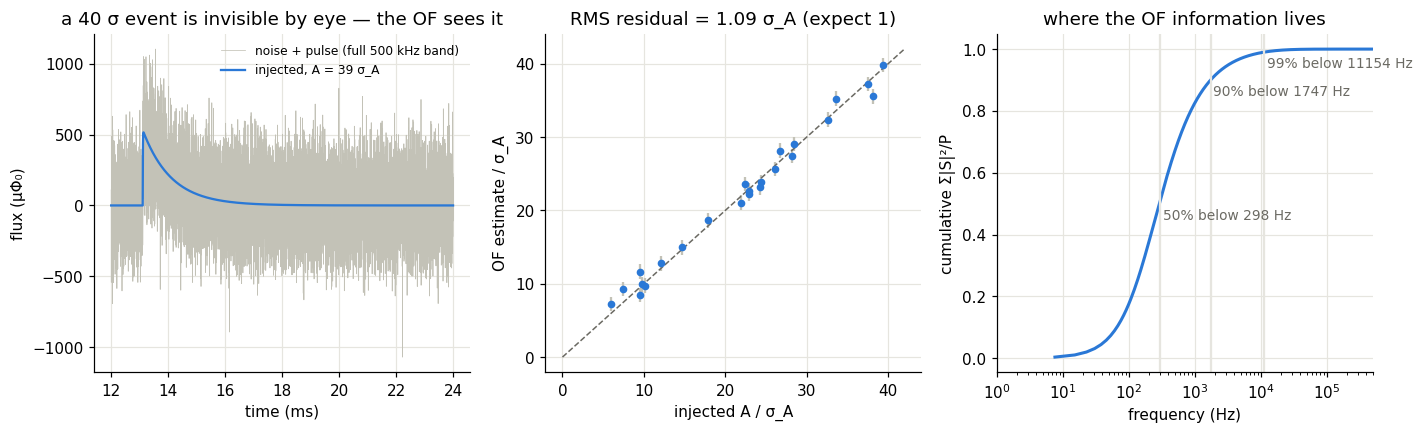

In [6]:
fit = A.fit_reference_pulse()
of = A.build_optimal_filter()                     # default grid; artifact regenerated in 0.3.1, analytic fallback otherwise
sigma_A = of.amplitude_resolution                 # baseline 1-sigma in template-amplitude units (new in 0.3.1)
print(f"pulse fit: tau_in = {fit.tau_in*1e6:.2f} µs, tau_t = {fit.tau_t*1e3:.2f} ms, log-RMS error = {fit.rms_log_error:.1e}")
print(f"OF baseline resolution sigma_A = {sigma_A:.3f} (template units; peak of a unit pulse = {of.template.max():.2f} µΦ₀)")

# inject known amplitudes, 5-40 sigma_A, on independent noise records; recover them
rng = np.random.default_rng(11)
snr = rng.uniform(5, 40, 24)
amps = snr * sigma_A
traces = gen.generate_ensemble(len(amps), N) + amps[:, None] * of.template[None, :]
est = np.array([of.estimate_amplitude(x) for x in traces])

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
tt = np.arange(N) / FS * 1e3
k = int(np.argmax(amps)); sl = slice(12000, 24000)
ax[0].plot(tt[sl], traces[k, sl], lw=0.5, color="#c3c2b7", label="noise + pulse (full 500 kHz band)")
ax[0].plot(tt[sl], amps[k] * of.template[sl], lw=1.5, color="#2a78d6", label=f"injected, A = {snr[k]:.0f} σ_A")
ax[0].set(xlabel="time (ms)", ylabel="flux (µΦ₀)", title="a 40 σ event is invisible by eye — the OF sees it"); ax[0].legend(frameon=False, fontsize=8)
ax[1].errorbar(snr, est / sigma_A, yerr=1.0, fmt="o", ms=4, color="#2a78d6", ecolor="#c3c2b7")
ax[1].plot([0, 42], [0, 42], "--", color="#6b6a63", lw=1)
ax[1].set(xlabel="injected A / σ_A", ylabel="OF estimate / σ_A", title=f"RMS residual = {np.std(est-amps)/sigma_A:.2f} σ_A (expect 1)")

fr = np.fft.rfftfreq(N, 1 / FS)
w = np.abs(of.template_fft) ** 2 / of.psd; w[0] = 0
cum = np.cumsum(w) / np.sum(w)
ax[2].semilogx(fr[1:], cum[1:], color="#2a78d6", lw=2)
for q in (0.5, 0.9, 0.99):
    fq = fr[np.searchsorted(cum, q)]
    ax[2].axvline(fq, color="#e6e5df"); ax[2].text(fq * 1.1, q - 0.05, f"{q:.0%} below {fq:.0f} Hz", fontsize=9, color="#6b6a63")
ax[2].set(xlim=(1, 5e5), xlabel="frequency (Hz)", ylabel="cumulative Σ|S|²/P", title="where the OF information lives")
plt.show()

In [7]:
# Which term limits the resolution? Recompute sigma_A with one component removed at a time.
S2 = np.abs(of.template_fft) ** 2
def sigma_from(psd):
    psd = psd.copy(); psd[0] = np.inf
    return 1.0 / np.sqrt(np.sum(S2[1:] / psd[1:]))
comp_psd = {k: np.interp(fr, f, asd ** 2, left=asd[0] ** 2) for k, (f, asd) in comps.items()}
s_all = sigma_from(sum(comp_psd.values()))
print(f"baseline sigma_A (all terms) = {s_all:.3e}")
for k in comp_psd:
    s = sigma_from(sum(v for kk, v in comp_psd.items() if kk != k))
    print(f"  without {k:8s}: sigma ratio {s / s_all:.3f}")
print("-> in this budget the detector is SQUID-(readout-)limited, not thermodynamically limited.")

baseline sigma_A (all terms) = 3.721e-05
  without Johnson : sigma ratio 0.989
  without SQUID   : sigma ratio 0.306
  without TD      : sigma ratio 0.950
  without Er      : sigma ratio 0.988
-> in this budget the detector is SQUID-(readout-)limited, not thermodynamically limited.


## 4. The readout-bandwidth decision

The budget runs to 30 MHz with a *white* SQUID+Johnson floor (≈ 0.093 µΦ₀²/Hz). Bringing it onto a 1 MHz DAQ grid requires a physical assumption:

* **band-limited readout** (FLL SQUID of a few MHz + fast digitiser with decimation, or an analogue anti-alias filter as in ECHo at ~100 kHz) → in-band interpolation;
* **no bandwidth limit** → every alias of the 30 MHz floor folds into the band, ≈ 60 copies of the white floor.

Before 0.3.1 the second was the script default. It raises the in-band PSD ×60 and the OF baseline σ ×5.7. It is now opt-in (`--alias-fold`), and the readout bandwidth can be stated with `--anti-alias-cutoff-hz`. This is the first question to settle with the DAQ group.

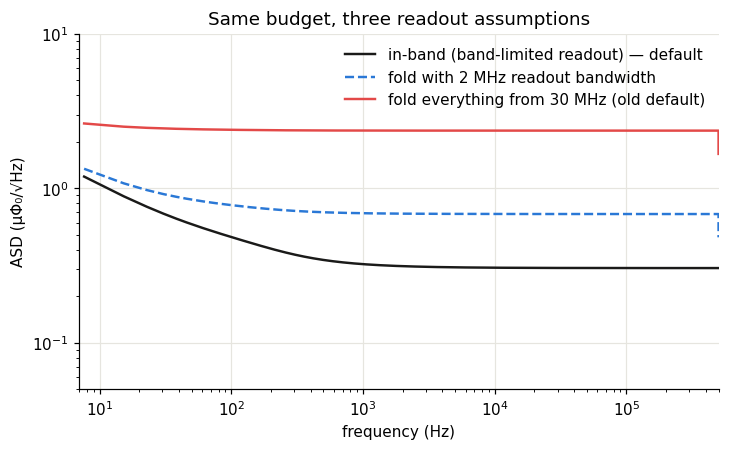

  in-band      sigma_A / sigma_A(in-band) = 1.00
  2 MHz fold   sigma_A / sigma_A(in-band) = 1.82
  full fold    sigma_A / sigma_A(in-band) = 5.69


In [8]:
tf, p_in, _   = pr.inband_resample_psd_density(f_nat, psd_nat, FS, N, allow_extrapolation=True)
_,  p_fold, _ = pr.alias_fold_psd_density(f_nat, psd_nat, FS, N)
_,  p_bl, _   = pr.alias_fold_psd_density(f_nat, psd_nat, FS, N, anti_alias_cutoff_hz=2e6, anti_alias_transition_hz=1e6)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
m = tf > 0
ax.loglog(tf[m], np.sqrt(p_in[m]),   color="#1a1a19", lw=1.6, label="in-band (band-limited readout) — default")
ax.loglog(tf[m], np.sqrt(p_bl[m]),   color="#2a78d6", lw=1.6, ls="--", label="fold with 2 MHz readout bandwidth")
ax.loglog(tf[m], np.sqrt(p_fold[m]), color="#e34948", lw=1.6, label="fold everything from 30 MHz (old default)")
ax.set(xlim=(7, 5e5), ylim=(0.05, 10), xlabel="frequency (Hz)", ylabel="ASD (µΦ₀/√Hz)", title="Same budget, three readout assumptions")
ax.legend(frameon=False); plt.show()

for label, p in [("in-band", p_in), ("2 MHz fold", p_bl), ("full fold", p_fold)]:
    print(f"  {label:12s} sigma_A / sigma_A(in-band) = {sigma_from(p) / sigma_from(p_in):.2f}")

## 5. Stressors: slow non-stationarity, lines, pile-up

Real DELight records are not stationary. The 1.25 eV prototype paper reports bath-temperature drifts strong enough that 26 % of events were discarded and a 0.04 % linear gain correction was needed. The package models that as a *level* modulation (`TemporalNoiseWrapper`) plus additive drift; since 0.3.1 the level is scaled through the correct knob (`psd_scale` for absolute spectra) and the metadata reports what was actually applied.

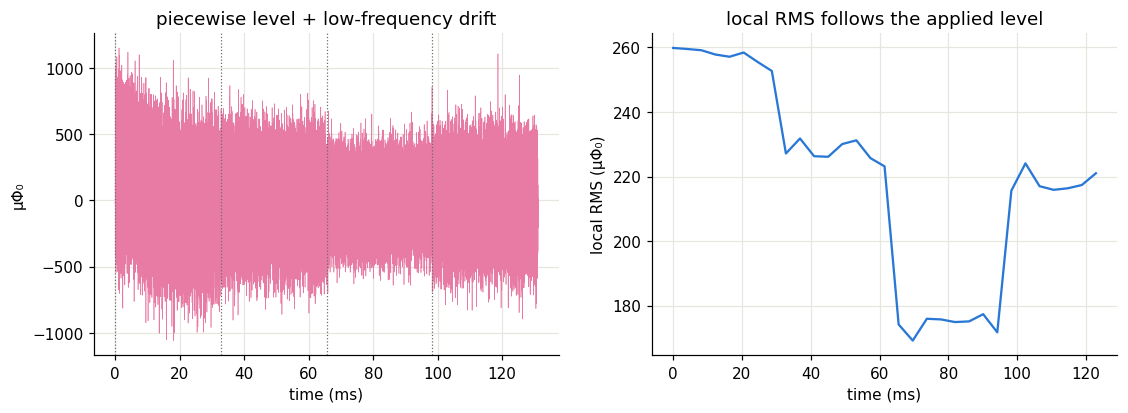

segment metadata (level_scale is the power ratio actually applied, through level_knob):
  [     0,  32768)  level_scale=1.405  knob=psd_scale  psd_scale=1.405
  [ 32768,  65536)  level_scale=1.115  knob=psd_scale  psd_scale=1.115
  [ 65536,  98304)  level_scale=0.654  knob=psd_scale  psd_scale=0.654
  [ 98304, 131072)  level_scale=1.008  knob=psd_scale  psd_scale=1.008


In [9]:
tw = TemporalNoiseWrapper({
    "mode": "piecewise", "n_segments": 4, "crossfade_len": 512,
    "noise_power_scale_range": [0.6, 1.6],          # power ratio per segment (bath-temperature excursions)
    "add_drift": True, "drift_type": "lowpass", "drift_cutoff_hz": 20.0, "drift_rms": 60.0,
    "sampling_frequency": FS,
}, seed=5)
y, tmeta = tw.generate_piecewise(N, gen, return_metadata=True)
y = tw.add_drift(y)

win = 4096
local_std = np.array([y[i:i+win].std() for i in range(0, N - win, win)])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(np.arange(N) / FS * 1e3, y, lw=0.4, color=C["sim"]); ax[0].set(xlabel="time (ms)", ylabel="µΦ₀", title="piecewise level + low-frequency drift")
for s in tmeta["segments"]:
    ax[0].axvline(s["start"] / FS * 1e3, color="#6b6a63", lw=0.8, ls=":")
ax[1].plot(np.arange(len(local_std)) * win / FS * 1e3, local_std, color="#2a78d6"); ax[1].set(xlabel="time (ms)", ylabel="local RMS (µΦ₀)", title="local RMS follows the applied level")
plt.show()
print("segment metadata (level_scale is the power ratio actually applied, through level_knob):")
for s in tmeta["segments"]:
    print(f"  [{s['start']:6d}, {s['end']:6d})  level_scale={s['level_scale']:.3f}  knob={s['level_knob']}  psd_scale={s['psd_scale']:.3f}")

Mains lines and glitches come from `ArtifactInjector` (deterministic sinusoids with random phase; point-process transients). **Pile-up** — the tails of preceding physical pulses inside a baseline window — is the artifact that dominates real baselines and is *not yet* a built-in template. Below it is emulated directly with the fitted pulse at a muon-like rate for a 40 cm² wafer at the surface (~0.7 Hz) to show what it does to the baseline spectrum; turning this into a proper injector template is the obvious next step.

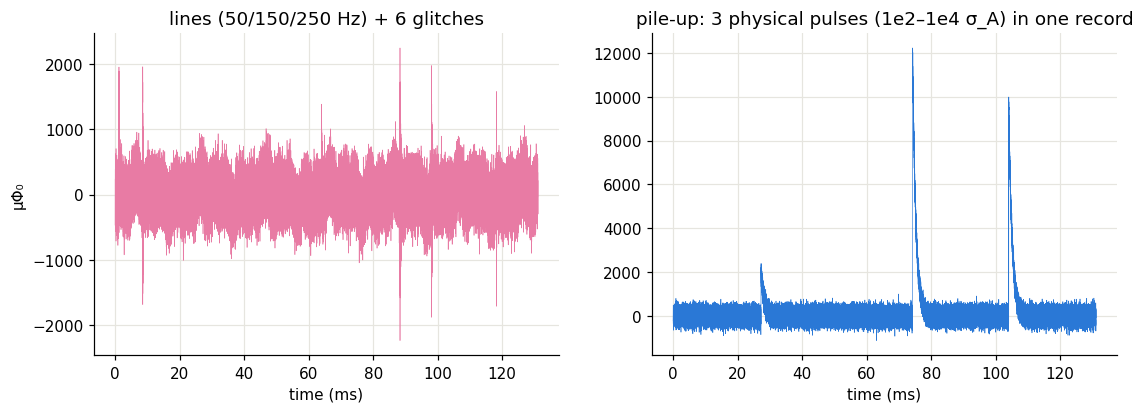

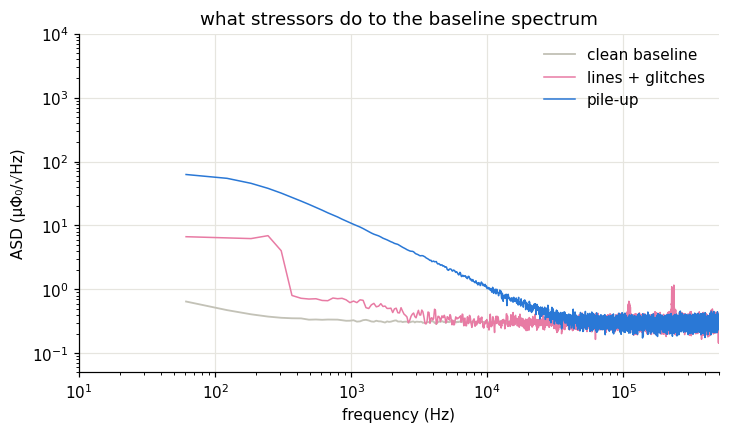

In [10]:
inj = ArtifactInjector({
    "sampling_frequency": FS, "enable_lines": True,
    "lines": [{"freq": 50.0, "amp": 0.4, "harmonics": [1, 3, 5]}],       # x baseline RMS (illustrative)
    "enable_glitches": True, "glitch_rate": 40.0, "glitch_amp_range": [4.0, 8.0],
    "glitch_templates": ["exp_decay", "damped_sine"], "glitch_duration_seconds": [2e-4, 1e-3],
    "amplitude_unit": "baseline_rms",
}, seed=9)
z, ameta = inj.apply(X[1], return_metadata=True)

# pile-up emulation with the *physical* pulse. Rates/energies are illustrative:
# 10 Hz of calibration + cosmic events (a 40 cm2, 300 um Si wafer at the surface
# alone sees ~0.7 Hz of muons depositing ~100 keV each), amplitudes 1e2-1e4 sigma_A
# (eV-scale resolution vs keV-scale events).
rate_hz, tt = 10.0, np.arange(N) / FS
rng = np.random.default_rng(3)
n_ev = max(rng.poisson(rate_hz * (N / FS + 5e-3)), 3)   # Poisson count, at least 3 so the effect is visible
pile = np.zeros(N)
for t0 in rng.uniform(-5e-3, N / FS, n_ev):       # pulses may start before the record
    pile += 10 ** rng.uniform(2, 4) * sigma_A * pulse_template_2(tt, t0, fit.An, fit.At, fit.tau_n, fit.tau_in, fit.tau_t)
zp = X[2] + pile

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(tt * 1e3, z, lw=0.4, color=C["sim"]); ax[0].set(xlabel="time (ms)", ylabel="µΦ₀", title=f"lines (50/150/250 Hz) + {ameta['glitches']['count']} glitches")
ax[1].plot(tt * 1e3, zp, lw=0.4, color="#2a78d6"); ax[1].set(xlabel="time (ms)", title=f"pile-up: {n_ev} physical pulses (1e2–1e4 σ_A) in one record")
plt.show()
fz, Pz = welch(z, fs=FS, nperseg=16384, detrend=False); fp, Pp = welch(zp, fs=FS, nperseg=16384, detrend=False)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.loglog(fw[ok], np.sqrt(Pw[ok]), color="#c3c2b7", lw=1.2, label="clean baseline")
ax.loglog(fz[1:], np.sqrt(Pz[1:]), color=C["sim"], lw=1.0, label="lines + glitches")
ax.loglog(fp[1:], np.sqrt(Pp[1:]), color="#2a78d6", lw=1.0, label="pile-up")
ax.set(xlim=(10, 5e5), ylim=(0.05, 1e4), xlabel="frequency (Hz)", ylabel="ASD (µΦ₀/√Hz)", title="what stressors do to the baseline spectrum")
ax.legend(frameon=False); plt.show()

## 6. Multichannel synthesis with a physical cross-spectrum

Correlation between MMC channels is *not* white: SQUID, Johnson, Er and TD noise are private to each sensor, while the bath temperature, pulse-tube microphonics, mains pickup and shared readout electronics are common and sit at low frequency or in lines. The right object is a frequency-dependent CSD, $\mathbf{S}(f)=\mathbf{L}(f)\mathbf{L}(f)^H$, which the package synthesises directly from low-rank factors. Below: four channels, each with the private four-term budget, plus one shared component (a low-frequency Lorentzian standing in for temperature/microphonics) and a shared 50 Hz line.

broadband time-domain correlation ch0-ch1: 0.034 | < 100 Hz band: 0.967


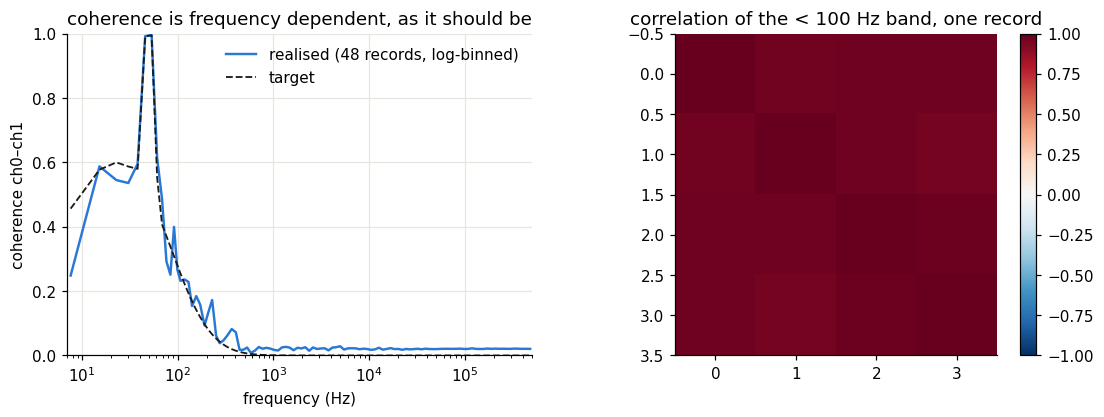

In [11]:
Cch = 4
fr = np.fft.rfftfreq(N, 1 / FS)
private_psd, _ = A.load_composite().evaluate(fr, FS / N, zero_dc=True)
shared_psd, _ = CompositeSpectrum([
    Lorentzian(scale=4.0, center_hz=0.0, half_width_hz=30.0, name="bath/microphonics"),
    Line(scale=300.0, frequency_hz=50.0, width_hz=3.0, name="mains"),
]).evaluate(fr, FS / N, zero_dc=True)

# factors L(f): (F, C, C+1) — private diagonal + one shared column with per-channel coupling gains
gains = np.array([1.0, 0.8, 1.2, 0.9])
L = np.zeros((fr.size, Cch, Cch + 1))
L[:, :, :Cch] = np.sqrt(private_psd)[:, None, None] * np.eye(Cch)[None]
L[:, :, Cch] = np.sqrt(shared_psd)[:, None] * gains[None, :]

mc = MultiChannelNoiseGenerator(gen.config, {"mode": "independent", "n_channels": Cch}, seed=21)
R = mc.generate_from_csd_factor(L, N, n_realizations=48)          # (48, 4, N)
diag = MultiChannelNoiseGenerator.csd_diagnostics(R, FS)
coh = diag["coherence"][:, 0, 1]
target_coh = (shared_psd * gains[0] * gains[1]) ** 2 / ((private_psd + gains[0]**2 * shared_psd) * (private_psd + gains[1]**2 * shared_psd) + 1e-30)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
# average the per-bin coherence estimate in log-spaced bins (single-bin estimates from 48 records scatter around a 1/48 bias)
edges = np.logspace(np.log10(fr[1]), np.log10(fr[-1]), 120)
idx = np.digitize(fr[1:], edges)
fb = np.array([fr[1:][idx == i].mean() for i in range(1, len(edges)) if np.any(idx == i)])
cb = np.array([coh[1:][idx == i].mean() for i in range(1, len(edges)) if np.any(idx == i)])
ax[0].semilogx(fb, cb, color="#2a78d6", lw=1.6, label="realised (48 records, log-binned)")
ax[0].semilogx(fr[1:], target_coh[1:], color="#1a1a19", lw=1.2, ls="--", label="target")
ax[0].set(xlim=(7, 5e5), ylim=(0, 1), xlabel="frequency (Hz)", ylabel="coherence ch0–ch1", title="coherence is frequency dependent, as it should be"); ax[0].legend(frameon=False)
# time-domain correlation is invisible broadband (shared power is a tiny fraction of the 500 kHz variance);
# band-limit to < 100 Hz to see the shared component
Fk = np.fft.rfft(R[0], axis=1); Fk[:, fr > 100.0] = 0
low = np.fft.irfft(Fk, n=N, axis=1)
im = ax[1].imshow(np.corrcoef(low), vmin=-1, vmax=1, cmap="RdBu_r"); ax[1].set(title="correlation of the < 100 Hz band, one record"); ax[1].grid(False); plt.colorbar(im, ax=ax[1])
print("broadband time-domain correlation ch0-ch1:", f"{np.corrcoef(R[0])[0,1]:.3f}", "| < 100 Hz band:", f"{np.corrcoef(low)[0,1]:.3f}")
plt.show()

## 7. What the model does not contain yet

Ordered by how much it is likely to matter for DELight's large-area wafer detectors:

1. **Bath-temperature fluctuations as a physical process** — coupled to gain (∂Φ/∂E), correlated across channels, calibrated to the measured ΔT/T ≈ 6×10⁻⁴; only a generic level/drift model exists.
2. **Pile-up as a first-class injector template** with the real event rate and energy spectrum; plus the He-atom adsorption heat load on the above-liquid wafers.
3. **Readout chain** — FLL bandwidth, second-stage/array SQUID and room-temperature amplifier terms, µMUX flux-ramp demodulation noise and its aliasing, crosstalk.
4. **The τ₀ (spin–electron) thermodynamic term** — the budget has one Lorentzian; the two-body model has two.
5. **Digitiser** — 16-bit quantisation, decimation-filter response; no µΦ₀ → ADC → eV calibration constants are carried in the config.
6. **Environmental lines and microphonics** calibrated to a measured DELight spectrum.
7. **Athermal / position-dependent pulse shapes** on phonon-collector wafers — a signal-model issue, invisible to a single `signal.dat`.

None of these is a flaw in the synthesiser; they are inputs the collaboration has and the simulator does not yet carry.

### References

- A. Fleischmann, C. Enss, G. M. Seidel, *Metallic magnetic calorimeters*, in *Cryogenic Particle Detection*, Springer (2005), doi:10.1007/10933596_4.
- S. Kempf, A. Fleischmann, L. Gastaldo, C. Enss, *Physics and applications of metallic magnetic calorimeters*, J. Low Temp. Phys. 193, 365 (2018), doi:10.1007/s10909-018-1891-6.
- B. von Krosigk et al., *DELight: a direct search experiment for light dark matter with superfluid helium*, SciPost Phys. Proc. 12, 016 (2023).
- DELight collaboration, MMC prototype with 1.25 eV FWHM, arXiv:2310.08512; bath-temperature drift study, arXiv:2310.08698.
- Er spin 1/f noise measurement, arXiv:2303.15257. ECHo two-stage SQUID readout and DAQ, arXiv:2102.11100. µMUX readout, arXiv:2509.07671, arXiv:2211.07127.
- D. McCammon, *Thermal equilibrium calorimeters — an introduction*, Springer (2005), doi:10.1007/10933596_1.
- F. Probst et al., two-exponential pulse model (1995), as implemented in Cait (arXiv:2207.02187); QETpy optimal filter.
- Package documents: `PAPER_CONVENTION.md`, `CONFIGURATION.md`, `AL2O3_AL_ATHERMAL_PLAN.md`, `CHANGELOG.md` (0.3.1).